# A/B Testing & Hypothesis Testing: Checkout Conversion Analysis

## Objective
Evaluate whether a redesigned checkout experience (Variant B) improves conversion rate compared with the existing checkout experience (Control A).

## Methodology
1. Load and inspect the experimental dataset.
2. Validate the data and identify the control and treatment groups.
3. Calculate sample sizes and conversion rates.
4. Formulate null and alternative hypotheses.
5. Conduct a two-proportion Z-test and a Chi-square test.
6. Calculate p-values, confidence intervals, and effect sizes.
7. Visualize the results.
8. Prepare an executive decision memo recommending whether to launch Variant B.

## Statistical significance
The significance level is set to 5% (α = 0.05).

## Dataset
`data/checkout_ab_test_v2.csv`

### Import libraries (Code)

In [6]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, norm
from statsmodels.stats.proportion import (
    proportions_ztest,
    proportion_confint,
    confint_proportions_2indep,
    proportion_effectsize
)
from statsmodels.stats.power import NormalIndPower

from IPython.display import display
from matplotlib.backends.backend_pdf import PdfPages

warnings.filterwarnings("ignore", category=FutureWarning)

### Project Directories

In [19]:
# Notebook location
BASE_DIR = Path.cwd()

# The notebook is inside the notebook folder
PROJECT_DIR = BASE_DIR.parent

# Dataset and output directories
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset location
DATA_PATH = DATA_DIR / "checkout_ab_test_v2.csv"

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

pd.set_option("display.max_columns", None)

print("Project directory:", PROJECT_DIR)
print("Dataset path:", DATA_PATH)
print("Output directory:", OUTPUT_DIR)
print("Dataset exists:", DATA_PATH.exists())

Project directory: c:\Users\singh\OneDrive\Desktop\Workora Internship Tasks\AB Testing & Hypothesis Testing
Dataset path: c:\Users\singh\OneDrive\Desktop\Workora Internship Tasks\AB Testing & Hypothesis Testing\data\checkout_ab_test_v2.csv
Output directory: c:\Users\singh\OneDrive\Desktop\Workora Internship Tasks\AB Testing & Hypothesis Testing\notebook\outputs
Dataset exists: True


### Load the dataset (Code)

In [20]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Check your data folder and CSV filename."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 1200
Columns: 8


,VisitorID,Variant,Timestamp,Device,TrafficSource,CheckoutStarted,Converted,OrderValueINR
0,VIS-00001,A,2026-07-10T14:33:00,Tablet,Paid,Yes,No,0
1,VIS-00002,B,2026-07-01T13:41:00,Tablet,Paid,No,No,0
2,VIS-00003,A,2026-07-18T04:55:00,Tablet,Paid,No,No,0
3,VIS-00004,B,2026-07-17T22:45:00,Desktop,Paid,No,No,0
4,VIS-00005,A,2026-07-17T23:44:00,Mobile,Direct,Yes,No,0


### Inspect the dataset

In [21]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique values in each column:")
for column in df.columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False).head(15))

Column names:
['VisitorID', 'Variant', 'Timestamp', 'Device', 'TrafficSource', 'CheckoutStarted', 'Converted', 'OrderValueINR']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   VisitorID        1200 non-null   str  
 1   Variant          1200 non-null   str  
 2   Timestamp        1200 non-null   str  
 3   Device           1200 non-null   str  
 4   TrafficSource    1200 non-null   str  
 5   CheckoutStarted  1200 non-null   str  
 6   Converted        1200 non-null   str  
 7   OrderValueINR    1200 non-null   int64
dtypes: int64(1), str(7)
memory usage: 75.1 KB

Missing values:


,Missing Values
VisitorID,0
Variant,0
Timestamp,0
Device,0
TrafficSource,0
CheckoutStarted,0
Converted,0
OrderValueINR,0



Duplicate rows: 0

Unique values in each column:

VisitorID
VisitorID
VIS-00001    1
VIS-00002    1
VIS-00003    1
VIS-00004    1
VIS-00005    1
VIS-00006    1
VIS-00007    1
VIS-00008    1
VIS-00009    1
VIS-00010    1
VIS-00011    1
VIS-00012    1
VIS-00013    1
VIS-00014    1
VIS-00015    1
Name: count, dtype: int64

Variant
Variant
A    600
B    600
Name: count, dtype: int64

Timestamp
Timestamp
2026-07-12T19:18:00    2
2026-07-14T09:13:00    2
2026-07-13T09:51:00    2
2026-07-07T16:30:00    2
2026-07-09T16:08:00    2
2026-07-02T10:39:00    2
2026-07-20T14:37:00    2
2026-07-17T00:44:00    2
2026-07-07T13:41:00    2
2026-07-05T06:13:00    2
2026-07-02T04:33:00    2
2026-07-15T21:27:00    2
2026-07-03T20:16:00    2
2026-07-20T15:17:00    2
2026-07-12T05:56:00    2
Name: count, dtype: int64

Device
Device
Mobile     431
Desktop    386
Tablet     383
Name: count, dtype: int64

TrafficSource
TrafficSource
Paid       309
Direct     309
Email      307
Organic    275
Name: count, dtype: 

### Clean and validate the dataset
Prepare the experimental data

In [22]:
# Work on a copy of the original dataset
analysis_df = df.copy()

# Convert timestamps to datetime
analysis_df["Timestamp"] = pd.to_datetime(
    analysis_df["Timestamp"],
    errors="coerce"
)

# Normalize experiment labels
analysis_df["Variant"] = (
    analysis_df["Variant"].astype(str).str.strip().str.upper()
)

# Convert Yes/No outcomes into binary values
binary_mapping = {
    "yes": 1,
    "no": 0
}

analysis_df["Converted_Binary"] = (
    analysis_df["Converted"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map(binary_mapping)
)

analysis_df["CheckoutStarted_Binary"] = (
    analysis_df["CheckoutStarted"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map(binary_mapping)
)

# Check the data
print("Variant counts:")
display(analysis_df["Variant"].value_counts())

print("\nConversion outcome counts:")
display(analysis_df["Converted"].value_counts())

print("\nInvalid conversion values:",
      analysis_df["Converted_Binary"].isna().sum())

print("Duplicate visitor IDs:",
      analysis_df["VisitorID"].duplicated().sum())

print("Invalid timestamps:",
      analysis_df["Timestamp"].isna().sum())

print("\nOrder value by conversion outcome:")
display(
    analysis_df.groupby("Converted")["OrderValueINR"]
    .agg(["count", "min", "max", "mean"])
)

# Verify logical consistency
print(
    "\nConverted visitors with zero order value:",
    (
        (analysis_df["Converted"] == "Yes")
        & (analysis_df["OrderValueINR"] <= 0)
    ).sum()
)

print(
    "Non-converted visitors with positive order value:",
    (
        (analysis_df["Converted"] == "No")
        & (analysis_df["OrderValueINR"] > 0)
    ).sum()
)

Variant counts:


Variant
A    600
B    600
Name: count, dtype: int64


Conversion outcome counts:


Converted
No     1072
Yes     128
Name: count, dtype: int64


Invalid conversion values: 0
Duplicate visitor IDs: 0
Invalid timestamps: 0

Order value by conversion outcome:


,count,min,max,mean
Converted,,,,
No,1072,0,0,0.00000
Yes,128,99,199,146.65625



Converted visitors with zero order value: 0
Non-converted visitors with positive order value: 0


### Finalize the analysis dataset

In [23]:
# Keep only the two intended experiment groups
analysis_df = analysis_df[
    analysis_df["Variant"].isin(["A", "B"])
].copy()

# The experiment requires a known group and conversion outcome
analysis_df = analysis_df.dropna(
    subset=["Variant", "Converted_Binary"]
).copy()

analysis_df["Converted_Binary"] = (
    analysis_df["Converted_Binary"].astype(int)
)

# Visitor-level independence check
if analysis_df["VisitorID"].duplicated().any():
    raise ValueError(
        "Duplicate visitor IDs detected. Resolve these before testing."
    )

if set(analysis_df["Variant"].unique()) != {"A", "B"}:
    raise ValueError("Both experiment variants A and B are required.")

if not analysis_df["Converted_Binary"].isin([0, 1]).all():
    raise ValueError("Conversion must be coded as 0 or 1.")

print("Final analysis dataset:", analysis_df.shape)
print("Unique visitors:", analysis_df["VisitorID"].nunique())
print("\nGroup counts:")
display(analysis_df["Variant"].value_counts().sort_index())

print("\nConversion counts:")
display(
    pd.crosstab(
        analysis_df["Variant"],
        analysis_df["Converted_Binary"],
        margins=True
    )
)

Final analysis dataset: (1200, 10)
Unique visitors: 1200

Group counts:


Variant
A    600
B    600
Name: count, dtype: int64


Conversion counts:


Converted_Binary,0,1,All
Variant,,,
A,543,57,600
B,529,71,600
All,1072,128,1200


### Calculate conversion rates

In [24]:
summary = (
    analysis_df.groupby("Variant")["Converted_Binary"]
    .agg(Visitors="count", Conversions="sum")
    .reindex(["A", "B"])
)

summary["Non_Conversions"] = (
    summary["Visitors"] - summary["Conversions"]
)

summary["Conversion_Rate"] = (
    summary["Conversions"] / summary["Visitors"]
)

summary["Conversion_Rate_Pct"] = (
    summary["Conversion_Rate"] * 100
)

display(summary.round(4))

n_a = int(summary.loc["A", "Visitors"])
n_b = int(summary.loc["B", "Visitors"])

x_a = int(summary.loc["A", "Conversions"])
x_b = int(summary.loc["B", "Conversions"])

p_a = x_a / n_a
p_b = x_b / n_b

absolute_lift = p_b - p_a

relative_lift = (
    (p_b - p_a) / p_a
    if p_a > 0 else np.nan
)

print(f"Control A conversion rate: {p_a:.2%}")
print(f"Variant B conversion rate: {p_b:.2%}")
print(f"Absolute conversion lift: {absolute_lift:.2%}")
print(
    f"Relative conversion lift: {relative_lift:.2%}"
    if np.isfinite(relative_lift)
    else "Relative lift undefined"
)

,Visitors,Conversions,Non_Conversions,Conversion_Rate,Conversion_Rate_Pct
Variant,,,,,
A,600,57,543,0.0950,9.5000
B,600,71,529,0.1183,11.8333


Control A conversion rate: 9.50%
Variant B conversion rate: 11.83%
Absolute conversion lift: 2.33%
Relative conversion lift: 24.56%


### Formulate the hypotheses

## Hypothesis Testing

Let \(p_A\) be the true purchase conversion rate of Control A and \(p_B\) be the true purchase conversion rate of Variant B.

**Null hypothesis (H₀):** \(p_A = p_B\)

There is no difference in the true conversion rates between the two checkout versions.

**Alternative hypothesis (H₁):** \(p_A \ne p_B\)

The true conversion rates differ between the two checkout versions.

**Significance level:** α = 0.05

**Confidence level:** 95%

We will use a two-sided, two-proportion Z-test and a Chi-square test of independence.

A p-value below 0.05 provides evidence against the null hypothesis. Statistical significance alone does not establish that the variant is profitable or worth launching.

### Run the statistical tests
Two-proportion Z-test

In [25]:
from statsmodels.stats.proportion import proportions_ztest

z_statistic, p_value_z = proportions_ztest(
    count=np.array([x_b, x_a]),
    nobs=np.array([n_b, n_a]),
    alternative="two-sided"
)

print("TWO-PROPORTION Z-TEST")
print("-" * 35)
print(f"Z-statistic: {z_statistic:.4f}")
print(f"P-value: {p_value_z:.6f}")
print(f"Significance level: {0.05}")

if p_value_z < 0.05:
    print("\nResult: Statistically significant difference.")
else:
    print("\nResult: No statistically significant difference detected.")

TWO-PROPORTION Z-TEST
-----------------------------------
Z-statistic: 1.3092
P-value: 0.190456
Significance level: 0.05

Result: No statistically significant difference detected.


### Chi-square test

In [26]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    analysis_df["Variant"],
    analysis_df["Converted_Binary"]
)

contingency_table.columns = ["Not Converted", "Converted"]

display(contingency_table)

chi2_statistic, p_value_chi2, degrees_freedom, expected = (
    chi2_contingency(
        contingency_table,
        correction=False
    )
)

print(f"Chi-square statistic: {chi2_statistic:.4f}")
print(f"Degrees of freedom: {degrees_freedom}")
print(f"P-value: {p_value_chi2:.6f}")

print("\nExpected counts under the null:")
display(
    pd.DataFrame(
        expected,
        index=contingency_table.index,
        columns=contingency_table.columns
    ).round(2)
)

print(
    "\nDifference between Z-test and Chi-square p-values:",
    abs(p_value_z - p_value_chi2)
)

,Not Converted,Converted
Variant,,
A,543,57
B,529,71


Chi-square statistic: 1.7141
Degrees of freedom: 1
P-value: 0.190456

Expected counts under the null:


,Not Converted,Converted
Variant,,
A,536.0,64.0
B,536.0,64.0



Difference between Z-test and Chi-square p-values: 3.747002708109903e-15


### Calculate confidence intervals and effect size
Confidence intervals

In [27]:
from statsmodels.stats.proportion import (
    proportion_confint,
    confint_proportions_2indep
)

ci_a = proportion_confint(
    x_a, n_a, alpha=0.05, method="wilson"
)

ci_b = proportion_confint(
    x_b, n_b, alpha=0.05, method="wilson"
)

# Difference is calculated as Variant B minus Control A
diff_ci_low, diff_ci_high = confint_proportions_2indep(
    count1=x_b,
    nobs1=n_b,
    count2=x_a,
    nobs2=n_a,
    compare="diff",
    method="newcomb",
    alpha=0.05
)

confidence_results = pd.DataFrame({
    "Variant": ["A - Control", "B - Variant"],
    "Conversion Rate": [p_a, p_b],
    "95% CI Lower": [ci_a[0], ci_b[0]],
    "95% CI Upper": [ci_a[1], ci_b[1]]
})

display(
    confidence_results.style.format({
        "Conversion Rate": "{:.2%}",
        "95% CI Lower": "{:.2%}",
        "95% CI Upper": "{:.2%}"
    })
)

print(
    f"Conversion lift (B - A): {absolute_lift:.2%}"
)
print(
    f"95% CI for lift: {diff_ci_low:.2%} to {diff_ci_high:.2%}"
)

,Variant,Conversion Rate,95% CI Lower,95% CI Upper
0,A - Control,9.50%,7.40%,12.11%
1,B - Variant,11.83%,9.49%,14.66%


Conversion lift (B - A): 2.33%
95% CI for lift: -1.18% to 5.85%


### Effect size

In [28]:
from statsmodels.stats.proportion import proportion_effectsize

cohens_h = proportion_effectsize(p_b, p_a)

print(f"Cohen's h: {cohens_h:.4f}")

if abs(cohens_h) < 0.2:
    print("Interpretation: Small standardized effect")
elif abs(cohens_h) < 0.5:
    print("Interpretation: Medium standardized effect")
elif abs(cohens_h) < 0.8:
    print("Interpretation: Large standardized effect")
else:
    print("Interpretation: Very large standardized effect")

Cohen's h: 0.0757
Interpretation: Small standardized effect


### Calculate sample size for a future experiment
**Sample-size estimation**

We'll estimate the sample needed to detect a 10% relative increase over the observed Control A conversion rate, with 80% power and a 5% two-sided significance level.

In [29]:
from statsmodels.stats.power import NormalIndPower

target_relative_lift = 0.10
target_power = 0.80
target_rate = p_a * (1 + target_relative_lift)

if p_a <= 0 or target_rate >= 1:
    print("Choose a valid baseline rate and target effect.")
else:
    effect_size = abs(
        proportion_effectsize(p_a, target_rate)
    )

    power_model = NormalIndPower()

    required_per_group = power_model.solve_power(
        effect_size=effect_size,
        power=target_power,
        alpha=0.05,
        ratio=1.0,
        alternative="two-sided"
    )

    required_per_group = int(np.ceil(required_per_group))

    print("Baseline conversion rate:", f"{p_a:.2%}")
    print("Target conversion rate:", f"{target_rate:.2%}")
    print("Power:", f"{target_power:.0%}")
    print("Significance level: 5%")
    print("Required visitors per group:", f"{required_per_group:,}")
    print(
        "Required total visitors:",
        f"{2 * required_per_group:,}"
    )

Baseline conversion rate: 9.50%
Target conversion rate: 10.45%
Power: 80%
Significance level: 5%
Required visitors per group: 15,612
Required total visitors: 31,224


### Generate visualizations
Conversion rate chart

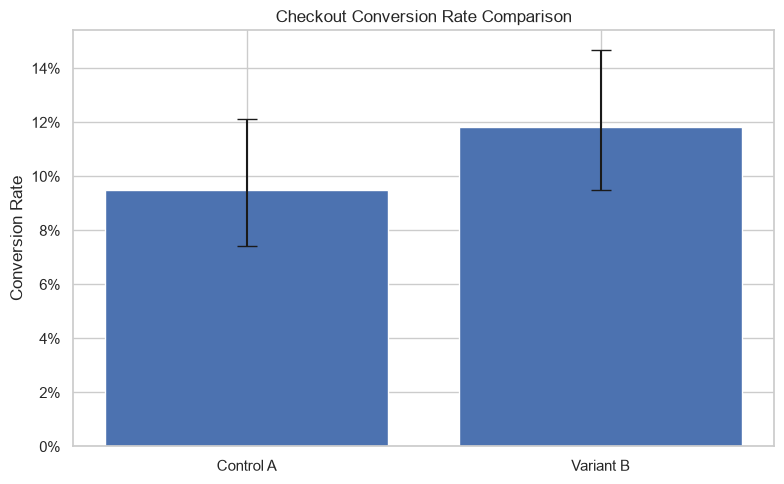

In [30]:
rates = [p_a, p_b]

lower_errors = [
    p_a - ci_a[0],
    p_b - ci_b[0]
]

upper_errors = [
    ci_a[1] - p_a,
    ci_b[1] - p_b
]

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    ["Control A", "Variant B"],
    rates,
    yerr=np.array([lower_errors, upper_errors]),
    capsize=7
)

ax.set_title("Checkout Conversion Rate Comparison")
ax.set_ylabel("Conversion Rate")
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "conversion_rates.png", dpi=150)
plt.show()

### Conversion lift chart

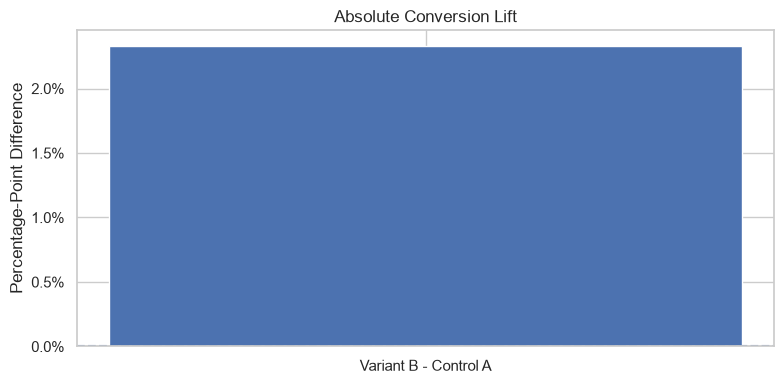

In [31]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    ["Variant B - Control A"],
    [absolute_lift]
)

ax.axhline(0, linestyle="--")
ax.set_title("Absolute Conversion Lift")
ax.set_ylabel("Percentage-Point Difference")
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.1%}")
)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "conversion_lift.png", dpi=150)
plt.show()

### Visitor outcome chart

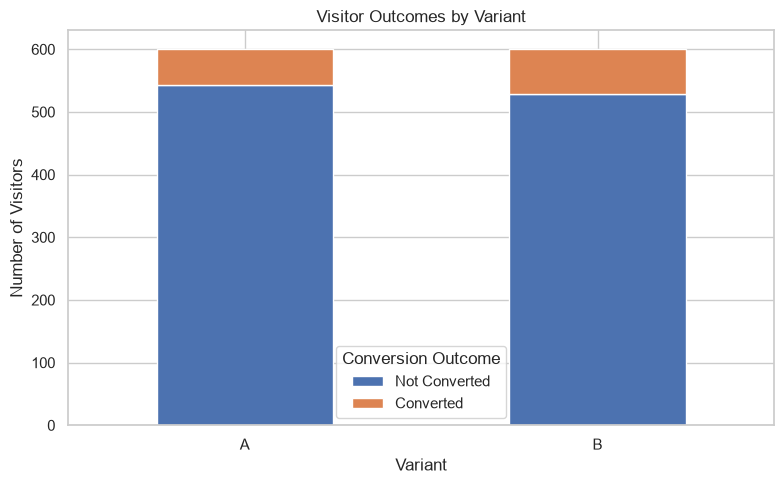

In [32]:
contingency_table.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Visitor Outcomes by Variant")
plt.xlabel("Variant")
plt.ylabel("Number of Visitors")
plt.xticks(rotation=0)
plt.legend(title="Conversion Outcome")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "visitor_outcomes.png", dpi=150)
plt.show()

### Additional business analysis
Segment analysis

In [33]:
# Conversion rate by device
device_results = (
    analysis_df.groupby(["Device", "Variant"])["Converted_Binary"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Visitors",
        "sum": "Conversions",
        "mean": "Conversion_Rate"
    })
)

display(device_results.round(4))

# Conversion rate by traffic source
source_results = (
    analysis_df.groupby(["TrafficSource", "Variant"])["Converted_Binary"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Visitors",
        "sum": "Conversions",
        "mean": "Conversion_Rate"
    })
)

display(source_results.round(4))

Visitors  Conversions  Conversion_Rate
Device  Variant                                        
Desktop A             195           20           0.1026
        B             191           20           0.1047
Mobile  A             208           19           0.0913
        B             223           27           0.1211
Tablet  A             197           18           0.0914
        B             186           24           0.1290

Visitors  Conversions  Conversion_Rate
TrafficSource Variant                                        
Direct        A             151           14           0.0927
              B             158           20           0.1266
Email         A             155           13           0.0839
              B             152           22           0.1447
Organic       A             141           15           0.1064
              B             134           10           0.0746
Paid          A             153           15           0.0980
              B             156           19           0.1218

### Revenue metrics

In [34]:
revenue_summary = (
    analysis_df.groupby("Variant")
    .agg(
        Visitors=("VisitorID", "nunique"),
        Conversions=("Converted_Binary", "sum"),
        Total_Revenue_INR=("OrderValueINR", "sum"),
        Average_Order_Value_INR=("OrderValueINR", "mean")
    )
)

revenue_summary["Conversion_Rate"] = (
    revenue_summary["Conversions"] / revenue_summary["Visitors"]
)

revenue_summary["Revenue_Per_Visitor_INR"] = (
    revenue_summary["Total_Revenue_INR"] / revenue_summary["Visitors"]
)

display(revenue_summary.round(2))

,Visitors,Conversions,Total_Revenue_INR,Average_Order_Value_INR,Conversion_Rate,Revenue_Per_Visitor_INR
Variant,,,,,,
A,600,57,8093,13.49,0.10,13.49
B,600,71,10679,17.80,0.12,17.80


### Executive decision memo

In [35]:
if p_value_z < 0.05 and diff_ci_low > 0:
    recommendation = (
        "Variant B shows a statistically significant positive conversion "
        "lift. Consider launching after reviewing costs and guardrail metrics."
    )
elif p_value_z < 0.05 and diff_ci_high < 0:
    recommendation = (
        "Variant B performs significantly worse. Keep Control A."
    )
else:
    recommendation = (
        "The experiment has not established a statistically significant "
        "difference. Keep Control A for now while reviewing power, costs, "
        "and whether additional data or a redesigned experiment is justified."
    )

memo = f"""
EXECUTIVE DECISION MEMO
Checkout A/B Testing Experiment

OBJECTIVE
Determine whether Variant B changes checkout purchase conversion.

RESULTS
Control A visitors: {n_a}
Control A conversions: {x_a}
Control A conversion rate: {p_a:.2%}

Variant B visitors: {n_b}
Variant B conversions: {x_b}
Variant B conversion rate: {p_b:.2%}

Absolute conversion lift: {absolute_lift:.2%}
Relative conversion lift: {
    f"{relative_lift:.2%}" if np.isfinite(relative_lift)
    else "Undefined"
}

Z-test statistic: {z_statistic:.4f}
Z-test p-value: {p_value_z:.6f}
Chi-square statistic: {chi2_statistic:.4f}
Chi-square p-value: {p_value_chi2:.6f}

95% confidence interval for conversion lift:
{diff_ci_low:.2%} to {diff_ci_high:.2%}

Cohen's h: {cohens_h:.4f}

RECOMMENDATION
{recommendation}

LIMITATIONS
The analysis assumes randomized assignment, independent visitors, and
correctly recorded conversion outcomes. Statistical significance does not
guarantee profitability. Revenue and implementation costs should also be
considered before a final rollout.
"""

print(memo)

(OUTPUT_DIR / "executive_decision_memo.txt").write_text(
    memo.strip(),
    encoding="utf-8"
)


EXECUTIVE DECISION MEMO
Checkout A/B Testing Experiment

OBJECTIVE
Determine whether Variant B changes checkout purchase conversion.

RESULTS
Control A visitors: 600
Control A conversions: 57
Control A conversion rate: 9.50%

Variant B visitors: 600
Variant B conversions: 71
Variant B conversion rate: 11.83%

Absolute conversion lift: 2.33%
Relative conversion lift: 24.56%

Z-test statistic: 1.3092
Z-test p-value: 0.190456
Chi-square statistic: 1.7141
Chi-square p-value: 0.190456

95% confidence interval for conversion lift:
-1.18% to 5.85%

Cohen's h: 0.0757

RECOMMENDATION
The experiment has not established a statistically significant difference. Keep Control A for now while reviewing power, costs, and whether additional data or a redesigned experiment is justified.

LIMITATIONS
The analysis assumes randomized assignment, independent visitors, and
correctly recorded conversion outcomes. Statistical significance does not
guarantee profitability. Revenue and implementation costs shoul

1043

### Export the PDF report

In [36]:
PDF_PATH = OUTPUT_DIR / "ab_test_report.pdf"

report_lines = [
    "A/B TESTING: CHECKOUT CONVERSION ANALYSIS",
    "",
    "EXECUTIVE SUMMARY",
    f"Control visitors: {n_a:,}",
    f"Control conversions: {x_a:,}",
    f"Control conversion rate: {p_a:.2%}",
    "",
    f"Variant visitors: {n_b:,}",
    f"Variant conversions: {x_b:,}",
    f"Variant conversion rate: {p_b:.2%}",
    "",
    f"Absolute lift: {absolute_lift:.2%}",
    f"Relative lift: {relative_lift:.2%}" if np.isfinite(relative_lift)
    else "Relative lift: Undefined",
    "",
    "STATISTICAL RESULTS",
    f"Z-statistic: {z_statistic:.4f}",
    f"Z-test p-value: {p_value_z:.6f}",
    f"Chi-square statistic: {chi2_statistic:.4f}",
    f"Chi-square p-value: {p_value_chi2:.6f}",
    f"95% CI for lift: {diff_ci_low:.2%} to {diff_ci_high:.2%}",
    f"Cohen's h: {cohens_h:.4f}",
    "",
    "EXECUTIVE RECOMMENDATION",
    recommendation,
    "",
    "LIMITATIONS",
    "Results depend on experiment validity and correct outcome recording.",
    "Statistical significance alone does not establish profitability."
]

with PdfPages(PDF_PATH) as pdf:
    # First page: summary and decision
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(
        0.08, 0.95,
        "\n".join(report_lines),
        ha="left",
        va="top",
        fontsize=10,
        family="monospace",
        linespacing=1.5
    )
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    # Additional pages: saved charts
    for chart_name in [
        "conversion_rates.png",
        "conversion_lift.png",
        "visitor_outcomes.png"
    ]:
        chart_path = OUTPUT_DIR / chart_name

        if chart_path.exists():
            img = plt.imread(chart_path)
            fig, ax = plt.subplots(figsize=(8.27, 5.85))
            ax.imshow(img)
            ax.axis("off")
            pdf.savefig(fig, bbox_inches="tight")
            plt.close(fig)

print("PDF report created:", PDF_PATH.resolve())
print("PDF exists:", PDF_PATH.exists())

PDF report created: C:\Users\singh\OneDrive\Desktop\Workora Internship Tasks\AB Testing & Hypothesis Testing\notebook\outputs\ab_test_report.pdf
PDF exists: True


In [37]:
print("FINAL PROJECT OUTPUTS")
print("=" * 40)

for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name}: {path.stat().st_size:,} bytes")

print("\nAnalysis completed.")

FINAL PROJECT OUTPUTS
ab_test_report.pdf: 83,529 bytes
conversion_lift.png: 28,401 bytes
conversion_rates.png: 31,142 bytes
executive_decision_memo.txt: 1,078 bytes
visitor_outcomes.png: 35,737 bytes

Analysis completed.
